# 03 · Modelagem e avaliação

Este notebook compara métodos de previsão, analisa onde o modelo escolhido erra, explica suas
previsões e mede a incerteza. Ele reproduz o que `python -m radar_dengue.model` faz em produção,
com mais detalhe.

**Desenho da avaliação**
- **Treino:** previsões cujo alvo cai antes de 2024 (2015 a 2023).
- **Teste:** previsões feitas a partir de janeiro de 2024, até 4 semanas antes do fim dos dados
  (as últimas semanas ainda recebem notificações atrasadas).
- **Horizontes:** 1, 2, 3 e 4 semanas à frente, um modelo para cada.
- **Métricas:** erro médio absoluto em casos (MAE), erro absoluto ponderado (WAPE: erro total ÷ casos
  totais) e erro quadrático médio em escala log (RMSE log, que dá peso parecido a todas as cidades).

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from radar_dengue import style
style.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import json
import lightgbm as lgb
import statsmodels.api as sm
from radar_dengue.features import FEATURES, add_targets, build_features, risk_level
from radar_dengue.model import PARAMS, split
from radar_dengue.geo import municipality_table, size_class, PORTES

raw = pd.read_parquet("data/raw/infodengue_sp.parquet")
d = add_targets(build_features(raw), [1, 2, 3, 4])
d = d.merge(municipality_table()[["geocode", "regiao"]], on="geocode", how="left")
d["porte"] = size_class(d.groupby("geocode")["pop"].transform("max"))
print(f"{len(FEATURES)} atributos:", ", ".join(FEATURES))

23 atributos: log_casos_lag0, log_casos_lag1, log_casos_lag2, log_casos_lag3, log_casos_lag52, log_media4, log_media8, crescimento_4s, inc100k_lag0, Rt, receptivo, tempmed_media4, tempmin_media4, tempmax_media4, umidmed_media4, umidmin_media4, umidmax_media4, tempmed_lag4, umidmed_lag4, sem_sin, sem_cos, log_pop, cresc_estado_4s


## 1. Métodos comparados

| Método | Ideia |
|---|---|
| **Ingênuo** | Os casos daqui a *h* semanas serão iguais aos desta semana. Difícil de bater no curto prazo. |
| **Sazonal ingênuo** | Os casos serão iguais aos da mesma semana do ano anterior. |
| **Regressão linear** | Mesmos 23 atributos e mesmo alvo do LightGBM (variação de log(casos)), mas com relações lineares. Testa se precisamos de machine learning. |
| **LightGBM** | *Gradient boosting* de árvores de decisão. Captura relações não lineares e interações, como "crescimento rápido + início do verão". |

Todos os métodos que aprendem (linear e LightGBM) preveem a **variação** de log(1 + casos) em relação
à semana atual. Prever o nível diretamente fazia o LightGBM subestimar a epidemia de 2024, porque
árvores não extrapolam além dos valores vistos no treino.

In [2]:
def metricas(real, prev):
    real, prev = np.asarray(real, float), np.clip(np.asarray(prev, float), 0, None)
    return {"MAE": np.mean(np.abs(real - prev)),
            "WAPE (%)": np.abs(real - prev).sum() / real.sum() * 100,
            "RMSE log": np.sqrt(np.mean((np.log1p(real) - np.log1p(prev)) ** 2))}

resultados, previsoes = [], {}
for h in [1, 2, 3, 4]:
    tr, te = split(d, h)
    y = f"y_h{h}"
    real = np.expm1(te[y]).to_numpy()
    atual = te["log_casos_lag0"].to_numpy()

    lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()
    p_lin = np.expm1(lin.predict(sm.add_constant(te[FEATURES])).to_numpy() + atual)
    gbm = lgb.LGBMRegressor(**PARAMS).fit(tr[FEATURES], tr[y] - tr["log_casos_lag0"])
    p_gbm = np.expm1(gbm.predict(te[FEATURES]) + atual)

    for nome, p in [("Ingênuo", np.expm1(atual)), ("Sazonal ingênuo", np.expm1(te["log_casos_lag52"])),
                    ("Regressão linear", p_lin), ("LightGBM", p_gbm)]:
        resultados.append({"horizonte": h, "método": nome, **metricas(real, p)})
    previsoes[h] = te.assign(real=real, prev=p_gbm.clip(0), naive=np.expm1(atual))
    if h == 4:
        modelo_h4, treino_h4 = gbm, tr

res = pd.DataFrame(resultados)
res.pivot(index="método", columns="horizonte", values="MAE").loc[
    ["Sazonal ingênuo", "Regressão linear", "Ingênuo", "LightGBM"]].round(1)

/tmp/ipykernel_524/3106952172.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


/tmp/ipykernel_524/3106952172.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


/tmp/ipykernel_524/3106952172.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


/tmp/ipykernel_524/3106952172.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


horizonte,1,2,3,4
método,,,,
Sazonal ingênuo,89.90,91.30,92.80,94.50
Regressão linear,20.40,29.50,36.60,42.40
Ingênuo,13.40,21.40,29.20,36.60
LightGBM,12.20,18.10,22.20,26.40


In [3]:
res.pivot(index="método", columns="horizonte", values="WAPE (%)").loc[
    ["Sazonal ingênuo", "Regressão linear", "Ingênuo", "LightGBM"]].round(1)

horizonte,1,2,3,4
método,,,,
Sazonal ingênuo,129.10,130.80,132.90,135.50
Regressão linear,29.40,42.30,52.40,60.80
Ingênuo,19.20,30.70,41.70,52.50
LightGBM,17.50,25.90,31.80,37.80


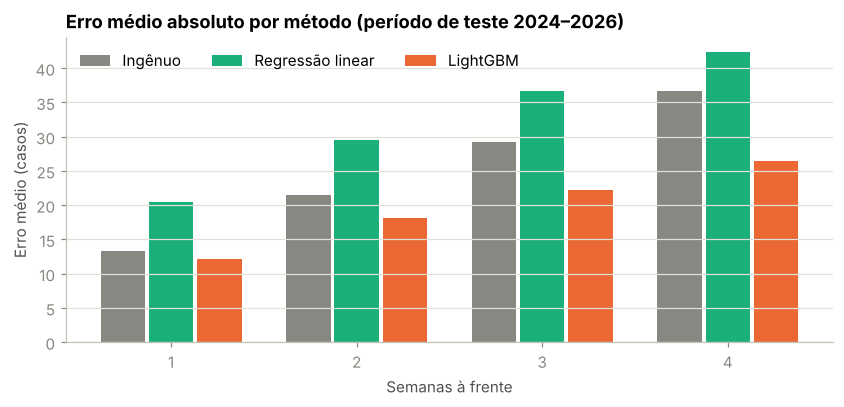

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
cores = {"Ingênuo": style.BASELINE, "Regressão linear": style.TERCEIRA, "LightGBM": style.PREVISTO}
larg = 0.26
for i, (nome, cor) in enumerate(cores.items()):
    v = res[res["método"] == nome].set_index("horizonte")["MAE"]
    ax.bar(v.index + (i - 1) * larg, v.values, width=larg * 0.92, color=cor, label=nome)
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Semanas à frente"); ax.set_ylabel("Erro médio (casos)")
ax.set_title("Erro médio absoluto por método (período de teste 2024–2026)")
ax.legend(ncols=3, loc="upper left"); plt.show()

**Leitura:**

- O **sazonal ingênuo** é o pior de longe: repetir o ano anterior não funciona quando os anos são tão
  diferentes entre si (2023 foi 5 vezes menor que 2024).
- A **regressão linear**, mesmo com todos os atributos, perde do ingênuo em todos os horizontes. As
  relações são não lineares: o efeito de "crescimento rápido" depende da época do ano e do tamanho
  da epidemia.
- O **LightGBM** é o melhor em todos os horizontes, e a vantagem cresce com o horizonte: cerca de
  9% menos erro que o ingênuo em 1 semana e 28% em 4 semanas. **Machine learning se justifica aqui.**
- O WAPE do LightGBM vai de cerca de 18% (1 semana) a 38% (4 semanas) dos casos totais. Prever
  dengue com 1 mês de antecedência continua difícil; o modelo reduz o erro, mas não o elimina.

O notebook 02 testa se essas diferenças são estatisticamente significativas.

## 2. Ajuste de hiperparâmetros

Testamos 6 configurações do LightGBM com **validação cruzada temporal** dentro do período de treino:
treina até o ano anterior e valida em 2021, depois em 2022, depois em 2023. O período de teste nunca é
usado nessa escolha. O resultado fica salvo em `models/tuning.json`; para refazer a busca (cerca de 5
minutos), mude `REFAZER` para `True`.

In [5]:
REFAZER = False
if REFAZER:
    grade = [dict(num_leaves=nl, min_child_samples=mc, learning_rate=lr, n_estimators=ne)
             for nl, mc, lr, ne in [(63, 50, 0.03, 600), (31, 100, 0.05, 400), (127, 50, 0.03, 600),
                                    (15, 200, 0.05, 500), (63, 200, 0.02, 1000), (255, 100, 0.03, 400)]]
    h, y = 4, "y_h4"
    b = d.dropna(subset=[y, "log_casos_lag52"])
    saida = []
    for g in grade:
        erros = []
        for ano in [2021, 2022, 2023]:
            tr = b[b["data_alvo_h4"] < f"{ano}-01-01"]
            va = b[(b["data_iniSE"] >= f"{ano}-01-01") & (b["data_alvo_h4"] < f"{ano + 1}-01-01")]
            m = lgb.LGBMRegressor(**{**PARAMS, **g}).fit(tr[FEATURES], tr[y] - tr["log_casos_lag0"])
            p = np.expm1(m.predict(va[FEATURES]) + va["log_casos_lag0"].to_numpy()).clip(0)
            erros.append(np.mean(np.abs(np.expm1(va[y]) - p)))
        saida.append([g, float(np.mean(erros))])
    json.dump(saida, open("models/tuning.json", "w"))

tuning = pd.DataFrame([{**g, "MAE validação (média 2021–2023)": e}
                       for g, e in json.load(open("models/tuning.json"))]).sort_values("MAE validação (média 2021–2023)")
tuning

,num_leaves,min_child_samples,learning_rate,n_estimators,MAE validação (média 2021–2023)
2,127,50,0.03,600,8.09
5,255,100,0.03,400,8.10
0,63,50,0.03,600,8.18
4,63,200,0.02,1000,8.19
1,31,100,0.05,400,8.23
3,15,200,0.05,500,8.24


As configurações ficam a cerca de 2% umas das outras (entre 8,1 e 8,2 casos de erro médio). A
configuração em uso (63 folhas, 600 árvores) está no meio do grupo, e a melhor seria só 1% superior,
diferença menor que a variação entre anos de validação. **O desempenho vem dos atributos e do
desenho do alvo, não do ajuste fino**, por isso mantivemos a configuração original, mais simples e
mais rápida.

## 3. Onde o modelo erra

### 3.1 Por porte do município (horizonte de 4 semanas)

In [6]:
p4 = previsoes[4]
def resumo(grupo):
    t = p4.groupby(grupo, observed=True).apply(lambda x: pd.Series({
        "municípios": x["geocode"].nunique(),
        "casos reais médios": x["real"].mean(),
        "MAE modelo": np.mean(np.abs(x["real"] - x["prev"])),
        "MAE ingênuo": np.mean(np.abs(x["real"] - x["naive"])),
        "WAPE modelo (%)": np.abs(x["real"] - x["prev"]).sum() / x["real"].sum() * 100}))
    t["redução do erro (%)"] = (1 - t["MAE modelo"] / t["MAE ingênuo"]) * 100
    return t
resumo("porte").round(1)

,municípios,casos reais médios,MAE modelo,MAE ingênuo,WAPE modelo (%),redução do erro (%)
porte,,,,,,
<20 mil,379.00,7.20,4.40,5.40,61.30,18.40
20–100 mil,184.00,44.30,20.00,26.00,45.10,23.00
100–500 mil,73.00,206.90,76.40,109.40,36.90,30.20
>500 mil,9.00,"2,112.70",678.00,980.80,32.10,30.90


- O modelo **melhora o erro em todos os portes**, de 18% nas cidades pequenas a cerca de 30%
  nas médias e grandes.
- O **erro relativo (WAPE) é maior nas cidades pequenas**: com poucos casos, qualquer diferença pesa
  muito em proporção. Nelas, a previsão vale mais como sinal de tendência do que como número exato.

### 3.2 Por região

In [7]:
resumo('regiao').round(1)

,municípios,casos reais médios,MAE modelo,MAE ingênuo,WAPE modelo (%),redução do erro (%)
regiao,,,,,,
Oeste,166.00,19.10,8.40,10.60,43.80,21.20
Centro,227.00,31.40,13.20,17.10,41.90,23.20
Leste,252.00,137.70,50.20,71.30,36.50,29.60


O ganho aparece nas três regiões e é maior no **Leste** (30% menos erro), justamente a região que
teve a epidemia atípica de 2024. O erro relativo (WAPE) também é menor no Leste, porque lá estão as
cidades grandes, cujas séries são mais suaves. No Oeste e no Centro, com muitas cidades pequenas, o
erro relativo é maior.

### 3.3 Por fase da epidemia

In [8]:
mudanca = np.log1p(p4["real"]) - np.log1p(p4["naive"])
p4["fase"] = np.select([mudanca > 0.4, mudanca < -0.4], ["Subida forte", "Queda forte"], "Estável")
fases = p4.groupby("fase").apply(lambda x: pd.Series({
    "% das observações": len(x) / len(p4) * 100,
    "MAE modelo": np.mean(np.abs(x["real"] - x["prev"])),
    "MAE ingênuo": np.mean(np.abs(x["real"] - x["naive"])),
    "viés modelo (prev − real)": np.mean(x["prev"] - x["real"])}))
fases["redução do erro (%)"] = (1 - fases["MAE modelo"] / fases["MAE ingênuo"]) * 100
fases.round(1)

,% das observações,MAE modelo,MAE ingênuo,viés modelo (prev − real),redução do erro (%)
fase,,,,,
Estável,43.90,23.10,12.70,-18.10,-80.90
Queda forte,30.00,11.30,54.60,3.60,79.20
Subida forte,26.10,49.30,56.30,-48.70,12.30


A fase é definida pela variação real em 4 semanas: "subida forte" quando os casos crescem mais de
cerca de 50% (variação acima de 0,4 em log), "queda forte" quando caem na mesma proporção.

- **Na fase estável, o ingênuo ganha.** É esperado: se os casos não mudam, "repetir a semana atual"
  é quase a resposta certa por definição. O modelo, que tenta antecipar mudanças, erra um pouco mais.
- **Nas quedas fortes, o modelo reduz o erro em cerca de 80%**: ele aprendeu que epidemias acabam
  depois do pico e no fim do verão, algo que o ingênuo não sabe.
- **Nas subidas fortes, o modelo ganha pouco (12%) e subestima** (viés negativo): antecipa parte do
  crescimento, mas não todo. É o erro mais caro para a vigilância, porque é quando a epidemia acelera.

Essa assimetria é o principal ponto a melhorar, por exemplo com casos nos municípios vizinhos, que
mostram a epidemia chegando antes.

### 3.4 Exemplo: a capital durante a epidemia de 2024

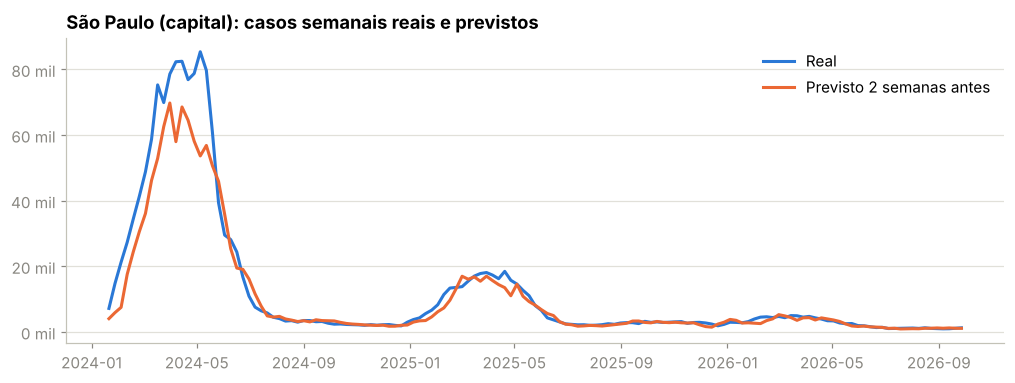

In [9]:
sp = previsoes[2].query("municipio == 'São Paulo'").sort_values("data_alvo_h2")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(sp["data_alvo_h2"], sp["real"], color=style.OBSERVADO, label="Real")
ax.plot(sp["data_alvo_h2"], sp["prev"], color=style.PREVISTO, label="Previsto 2 semanas antes")
ax.set_title("São Paulo (capital): casos semanais reais e previstos")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} mil"); ax.legend(); plt.show()

## 4. Explicabilidade

### 4.1 O que o modelo usa, em média

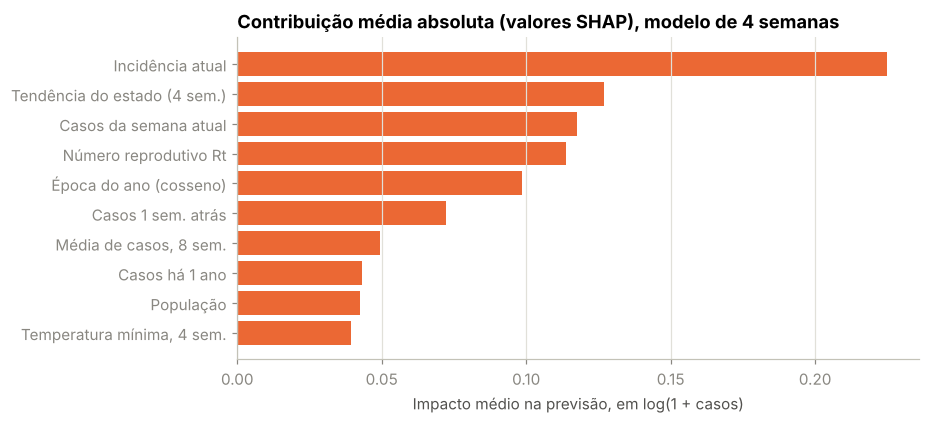

In [10]:
amostra = previsoes[4].sample(20000, random_state=0)
contrib = modelo_h4.predict(amostra[FEATURES], pred_contrib=True)[:, :-1]
shap_medio = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values()

nomes = {"inc100k_lag0": "Incidência atual", "cresc_estado_4s": "Tendência do estado (4 sem.)",
         "sem_cos": "Época do ano (cosseno)", "sem_sin": "Época do ano (seno)", "Rt": "Número reprodutivo Rt",
         "log_media8": "Média de casos, 8 sem.", "log_media4": "Média de casos, 4 sem.",
         "log_casos_lag0": "Casos da semana atual", "crescimento_4s": "Crescimento em 4 sem.",
         "tempmin_media4": "Temperatura mínima, 4 sem.", "log_casos_lag52": "Casos há 1 ano",
         "log_pop": "População", "log_casos_lag1": "Casos 1 sem. atrás",
         "log_casos_lag2": "Casos 2 sem. atrás", "log_casos_lag3": "Casos 3 sem. atrás"}
top = shap_medio.tail(10)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([nomes.get(f, f) for f in top.index], top.values, color=style.PREVISTO)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Contribuição média absoluta (valores SHAP), modelo de 4 semanas")
ax.set_xlabel("Impacto médio na previsão, em log(1 + casos)"); plt.show()

Os valores **SHAP** decompõem cada previsão na contribuição de cada atributo (o LightGBM calcula
isso exatamente com `pred_contrib=True`). Em média, o que mais move a previsão é a **incidência
atual**, a **tendência do estado**, os **casos recentes**, o **Rt** e a **época do ano**. O clima
aparece por último entre os dez mais importantes, coerente com o notebook 02: depois de saber a
época do ano e a situação atual, a temperatura acrescenta pouca informação.

### 4.2 Uma previsão explicada

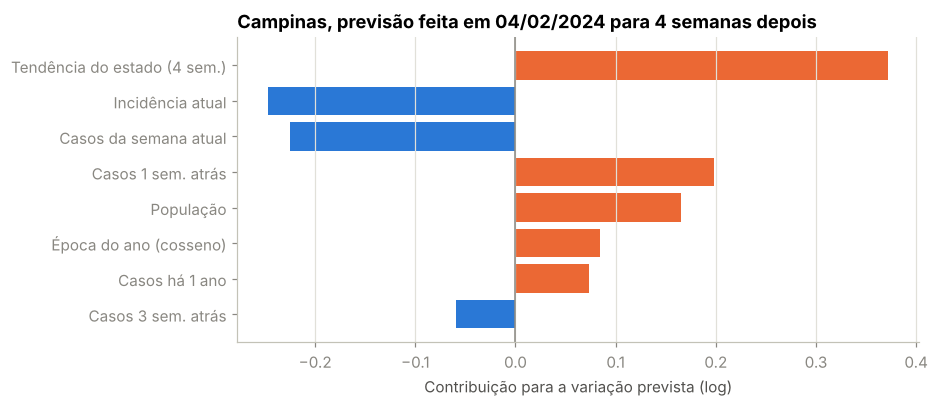

Casos na semana da previsão: 2,432 | previstos: 3,136 | reais: 6,550


In [11]:
ex = previsoes[4].query("municipio == 'Campinas'").sort_values("data_iniSE")
ex = ex[ex["data_iniSE"] == pd.Timestamp("2024-02-04")]
c = pd.Series(modelo_h4.predict(ex[FEATURES], pred_contrib=True)[0][:-1], index=FEATURES)
c = c.reindex(c.abs().sort_values().index).tail(8)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([nomes.get(f, f) for f in c.index], c.values,
        color=[style.PREVISTO if v > 0 else style.OBSERVADO for v in c.values])
ax.axvline(0, color="#898781", linewidth=1); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Campinas, previsão feita em 04/02/2024 para 4 semanas depois")
ax.set_xlabel("Contribuição para a variação prevista (log)"); plt.show()
print(f"Casos na semana da previsão: {np.expm1(ex['log_casos_lag0'].iloc[0]):,.0f} | "
      f"previstos: {ex['prev'].iloc[0]:,.0f} | reais: {ex['real'].iloc[0]:,.0f}")

Em fevereiro de 2024, no começo da epidemia recorde, Campinas tinha cerca de 2.400 casos por semana.
O modelo previu cerca de 3.100 para 4 semanas depois; o real foi cerca de 6.500.

As barras mostram por quê. A **tendência de alta no estado** empurrou a previsão para cima (laranja),
mas a **incidência atual já alta** puxou para baixo (azul): no histórico de treino, níveis altos
costumavam ser seguidos de estabilização. Em 2024 isso não aconteceu. É um exemplo concreto do viés
nas subidas fortes visto na seção 3.3, e é esse tipo de explicação que permite a um gestor de saúde
entender, e questionar, um alerta.

## 5. Incerteza: intervalos de previsão

Uma previsão de "45 casos" esconde quanto ela pode errar. Treinamos dois modelos adicionais com
**regressão quantílica** (objetivo `quantile` do LightGBM), para os percentis 10 e 90. O intervalo
entre eles deveria conter o valor real em cerca de **80%** dos casos.

In [12]:
tr4, te4 = split(d, 4)
q = {}
for a in [0.1, 0.9]:
    mq = lgb.LGBMRegressor(**{**PARAMS, "objective": "quantile", "alpha": a}).fit(
        tr4[FEATURES], tr4["y_h4"] - tr4["log_casos_lag0"])
    q[a] = np.expm1(mq.predict(te4[FEATURES]) + te4["log_casos_lag0"].to_numpy()).clip(0)
real4 = np.expm1(te4["y_h4"]).to_numpy()
dentro = (real4 >= q[0.1]) & (real4 <= q[0.9])
cob = pd.DataFrame({"porte": size_class(te4.groupby("geocode")["pop"].transform("max")).values, "dentro": dentro})
print(f"Cobertura do intervalo de 80%: {dentro.mean():.1%}")
cob.groupby("porte", observed=True)["dentro"].mean().mul(100).round(1).rename("cobertura (%)").to_frame()

Cobertura do intervalo de 80%: 75.6%


,cobertura (%)
porte,
<20 mil,78.20
20–100 mil,72.80
100–500 mil,69.60
>500 mil,62.60


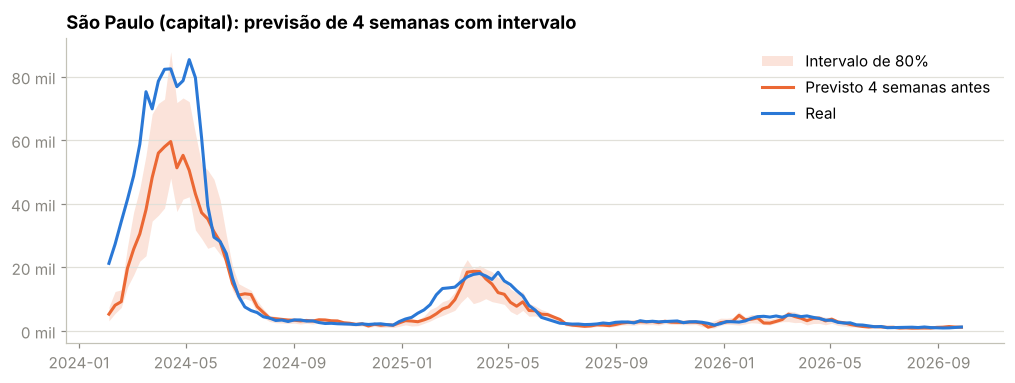

In [13]:
spq = te4.assign(real=real4, q10=q[0.1], q90=q[0.9]).query("municipio == 'São Paulo'").sort_values("data_alvo_h4")
spq["prev"] = previsoes[4].query("municipio == 'São Paulo'").sort_values("data_alvo_h4")["prev"].values
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(spq["data_alvo_h4"], spq["q10"], spq["q90"], color=style.PREVISTO, alpha=0.18, linewidth=0, label="Intervalo de 80%")
ax.plot(spq["data_alvo_h4"], spq["prev"], color=style.PREVISTO, label="Previsto 4 semanas antes")
ax.plot(spq["data_alvo_h4"], spq["real"], color=style.OBSERVADO, label="Real")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} mil")
ax.set_title("São Paulo (capital): previsão de 4 semanas com intervalo"); ax.legend(); plt.show()

A cobertura geral fica um pouco abaixo dos 80% nominais (cerca de 76%), porque 2024 foi mais extremo
que tudo no treino. Ela é boa nas cidades pequenas (78%) e pior nas grandes (63%): para as cidades
grandes, os intervalos são estreitos demais e precisariam de calibração adicional. Esses intervalos foram incorporados ao
dashboard, para que o usuário veja a faixa provável e não só um número.

## Conclusões

1. **LightGBM é o melhor método em todos os horizontes**; regressão linear e repetição do ano anterior
   perdem até do baseline ingênuo.
2. **O ganho cresce com o horizonte**: 9% menos erro em 1 semana e 28% em 4 semanas.
3. **Hiperparâmetros importam pouco** (cerca de 2% de diferença); o que importa é prever a variação, e
   não o nível.
4. **Principal fraqueza:** subestimar subidas fortes. O maior ganho está em reconhecer o fim das epidemias.
5. **Os intervalos de 80% cobrem cerca de 76%** dos casos reais: razoável no geral, mas estreitos
   demais nas cidades grandes.

**Próximos passos de modelagem:** casos nos municípios vizinhos, calibração dos intervalos (*conformal
prediction*) e ajuste do limiar de alerta priorizando o *recall*.